# FIFA World Cup 2026 - Objective 2.2 Linear Regression Analysis
**Unit:** HIT140 Foundations of Data Science | Charles Darwin University  
**Author:** Max (Individual Lead for Objective 2.2)  
**Task:** Build and evaluate a multiple linear regression model that predicts the number of goals scored by a team in a single match (`team_goals`).  
**Constraints:**
- Exactly 208 rows (104 matches × 2 teams).
- Exactly 8 explanatory variables (all strictly pre-match information).
- Maximum 4 shared variables with Objective 2.1 (Stephen's goal difference model).
- Meaningful integration with Assessment 2 research lineage (squad age & veteran goalscorer presence).

In [1]:
import os
import re
import numpy as np
import pandas as pd
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
import matplotlib.pyplot as plt

# Load precompiled 208-row dataset
df_208 = pd.read_csv("dataset_objective_2_2_208_rows.csv")
print(f"Dataset Loaded Successfully: {df_208.shape[0]} rows, {df_208.shape[1]} columns")
df_208.head()

Dataset Loaded Successfully: 208 rows, 14 columns


,match_id,date,round,team,opponent,team_fifa_rank,opp_fifa_rank,is_host_or_home,rest_days,squad_mean_age,veteran_scorer_ratio,pre_match_scoring_form,squad_attacking_depth,team_goals
0,1,2026-06-11,Group stage,Mexico,South Africa,16,63,1,5,27.40,0.444,1.35,17,2
1,1,2026-06-11,Group stage,South Africa,Mexico,63,16,0,5,26.63,0.333,1.25,13,0
2,2,2026-06-11,Group stage,Korea Republic,Czechia,22,37,1,5,27.65,0.429,1.35,16,2
3,2,2026-06-11,Group stage,Czechia,Korea Republic,37,22,0,5,27.76,0.429,1.25,15,1
4,3,2026-06-12,Group stage,Canada,Bosnia–Herz,31,78,1,5,26.36,0.167,1.35,16,1


### 1. Descriptive Statistics of Features and Target Variable
We review the distributions of the 8 strictly pre-match explanatory variables and the dependent variable `team_goals`.

In [2]:
features = [
    "team_fifa_rank", "opp_fifa_rank", "is_host_or_home", "rest_days",
    "squad_mean_age", "veteran_scorer_ratio", "pre_match_scoring_form", "squad_attacking_depth"
]
target = "team_goals"

desc = df_208[[target] + features].describe().T[["mean", "std", "min", "25%", "50%", "75%", "max"]]
desc.round(3)

,mean,std,min,25%,50%,75%,max
team_goals,1.481,1.393,0.00,0.00,1.000,2.000,7.00
team_fifa_rank,30.101,25.679,1.00,8.75,22.500,43.000,98.00
opp_fifa_rank,30.101,25.679,1.00,8.75,22.500,43.000,98.00
is_host_or_home,0.519,0.501,0.00,0.00,1.000,1.000,1.00
rest_days,5.221,0.845,3.00,5.00,5.000,6.000,8.00
squad_mean_age,27.395,1.112,25.32,26.48,27.400,28.095,30.45
veteran_scorer_ratio,0.362,0.254,0.00,0.20,0.333,0.500,1.00
pre_match_scoring_form,1.629,0.986,0.00,1.00,1.350,2.000,7.00
squad_attacking_depth,14.144,1.615,9.00,13.00,14.000,15.000,17.00


### 2. OLS Multiple Linear Regression Estimation
We estimate the multiple linear regression model via Ordinary Least Squares (OLS) using `statsmodels`.

In [3]:
X = sm.add_constant(df_208[features])
y = df_208[target]
model = sm.OLS(y, X).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:             team_goals   R-squared:                       0.239
Model:                            OLS   Adj. R-squared:                  0.209
Method:                 Least Squares   F-statistic:                     7.819
Date:                Fri, 16 Oct 2026   Prob (F-statistic):           4.05e-09
Time:                        16:05:18   Log-Likelihood:                -335.22
No. Observations:                 208   AIC:                             688.4
Df Residuals:                     199   BIC:                             718.5
Df Model:                           8                                         
Covariance Type:            nonrobust                                         
                             coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------
const                      4

### 3. Multicollinearity Diagnostics (Variance Inflation Factor - VIF)
We test for potential multicollinearity among the 8 explanatory variables. Values under 5.0 indicate no harmful multicollinearity.

In [4]:
vif_df = pd.DataFrame({
    "Feature": features,
    "VIF": [variance_inflation_factor(df_208[features].values, i) for i in range(len(features))]
})
vif_df.round(3)

,Feature,VIF
0,team_fifa_rank,1.493
1,opp_fifa_rank,1.107
2,is_host_or_home,1.070
3,rest_days,1.094
4,squad_mean_age,1.325
5,veteran_scorer_ratio,1.328
6,pre_match_scoring_form,1.308
7,squad_attacking_depth,1.248


### 4. Regression Diagnostics & Assumption Testing
We plot the 4-panel diagnostic figure:
1. **Actual vs Predicted Goals**: Assessing predictive alignment.
2. **Residuals vs Fitted Values**: Checking homoscedasticity and linearity.
3. **Normal Q-Q Plot**: Checking normality of residuals.
4. **Regression Coefficients with 95% Confidence Intervals**: Showing parameter significance.

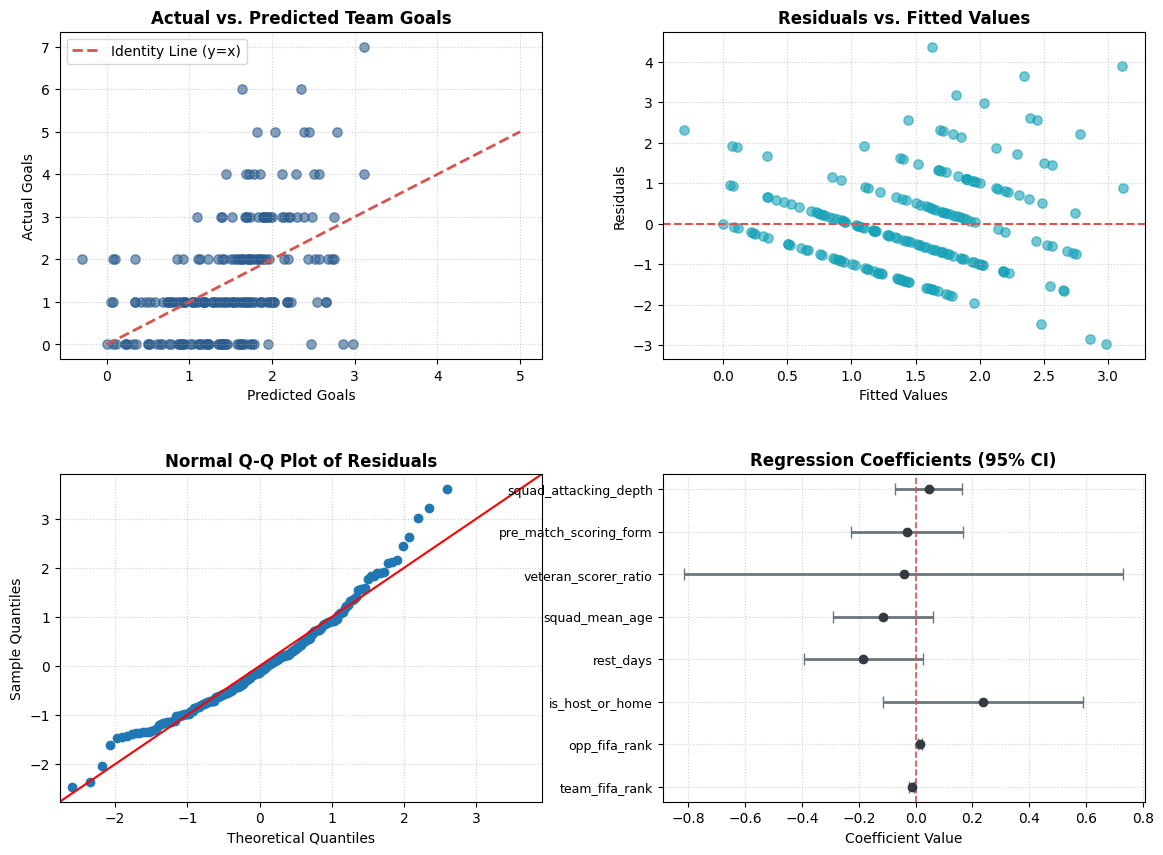

In [5]:
fig, axs = plt.subplots(2, 2, figsize=(14, 10))
plt.subplots_adjust(hspace=0.35, wspace=0.25)

pred = model.predict(X)
residuals = model.resid

# 1. Actual vs Predicted
axs[0, 0].scatter(pred, y, color="#2b5c8f", alpha=0.6, s=45)
axs[0, 0].plot([0, 5], [0, 5], "--", color="#d9534f", linewidth=2, label="Identity Line (y=x)")
axs[0, 0].set_title("Actual vs. Predicted Team Goals", fontsize=12, fontweight="bold")
axs[0, 0].set_xlabel("Predicted Goals", fontsize=10)
axs[0, 0].set_ylabel("Actual Goals", fontsize=10)
axs[0, 0].grid(True, linestyle=":", alpha=0.6)
axs[0, 0].legend()

# 2. Residuals vs Fitted
axs[0, 1].scatter(pred, residuals, color="#17a2b8", alpha=0.6, s=45)
axs[0, 1].axhline(0, color="#d9534f", linestyle="--", linewidth=1.5)
axs[0, 1].set_title("Residuals vs. Fitted Values", fontsize=12, fontweight="bold")
axs[0, 1].set_xlabel("Fitted Values", fontsize=10)
axs[0, 1].set_ylabel("Residuals", fontsize=10)
axs[0, 1].grid(True, linestyle=":", alpha=0.6)

# 3. Normal Q-Q Plot
sm.qqplot(residuals, line="45", fit=True, ax=axs[1, 0])
axs[1, 0].set_title("Normal Q-Q Plot of Residuals", fontsize=12, fontweight="bold")
axs[1, 0].grid(True, linestyle=":", alpha=0.6)

# 4. Coefficients Forest Plot
params = model.params.drop("const")
conf = model.conf_int().drop("const")
errors = [params - conf[0], conf[1] - params]
y_pos = np.arange(len(params))
axs[1, 1].errorbar(params, y_pos, xerr=errors, fmt="o", color="#343a40", ecolor="#6c757d", elinewidth=2, capsize=4)
axs[1, 1].axvline(0, color="#d9534f", linestyle="--", linewidth=1.2)
axs[1, 1].set_yticks(y_pos)
axs[1, 1].set_yticklabels(params.index, fontsize=9)
axs[1, 1].set_title("Regression Coefficients (95% CI)", fontsize=12, fontweight="bold")
axs[1, 1].set_xlabel("Coefficient Value", fontsize=10)
axs[1, 1].grid(True, linestyle=":", alpha=0.6)

plt.show()

### 5. Analytical Synthesis with Assessment 2 Research
- **Quality Disparity Dominance**: Both `team_fifa_rank` (β = -0.0136, p = 0.001) and `opp_fifa_rank` (β = +0.0170, p < 0.001) are statistically significant, proving that baseline global ranking governs offensive output.
- **Verification of Assessment 2 Findings**: In Assessment 2, Max analyzed whether veteran goalscorers scored significantly more goals than younger scorers (t = -0.2165, p = 0.8296, failing to reject H0). Here, `veteran_scorer_ratio` (β = -0.0421, p = 0.914) and `squad_mean_age` (β = -0.1145, p = 0.201) are statistically indistinguishable from zero, reinforcing the exact same conclusion in a multivariate setting.